---
format:
  html: default
---

# A4: Integrating differential equations (group project) {.unnumbered}

Assignment 4: Group project: numerical integration applied to initial value problems </br>
Published: <b>2 Nov</b>

<div class="alert alert-block alert-info">
<b>Note:</b>
<ul>
  <li>Complete the following and submit to Canvas before <b>6 Nov, 23:59</b>.</li>
  <li>Late work will receive 0%.</li>
  <li>Each assignment is worth the same.</li>
  <li><b>This is a group project: see Canvas for the group allocations.</b> Submit <b>one</b> notebook per group and list every group member below. Every member should contribute to, and be able to explain, every part of the submission.</li>
  <li>Please get in contact with the TA/instructor in plenty of time if you need help.</li>
  <li>Before submitting your work, make sure to check everything runs as expected. Click <b>Kernel &gt; Restart Kernel and Run All Cells</b>. Submit your notebook in .pdf format by clicking <b>File &gt; Export Notebook As &gt; PDF</b> or by printing to PDF in the browser.</li>
  <li>Feel free to add more cells to experiment or test your answers.</li>
  <li>I encourage you to discuss the course material and assignment questions with your classmates in other groups. However, each group must write up its own solutions.</li>
  <li>If you are the group leader (randomly assigned on canvas), please send an update after Monday's lecture time and I will provide further hints if required. 
  </li>
</ul>
</div>

<div class="custom-lecture-buttons my-3 d-flex gap-2">
  <a href="https://raw.githubusercontent.com/jackrthomas/Math5485/main/assignments/A04.ipynb" class="btn-download-ipynb btn btn-outline-primary btn-sm" target="_blank">
    <i class="bi bi-journal-code"></i> Download (.ipynb)
  </a>
</div>

The assignment is worth **100 pts**, plus up to **10 bonus pts** for the optional sections at the end (total $=\min\{ 100, \text{score} \}$). The symbols ✍️, 💻 indicate theory ($\LaTeX$), practice (code), respectively.

In [1]:
Names = ["Chongwei Chen", "Xuege Xu", "Stanley Wang"]

3-element Vector{String}:
 "Chongwei Chen"
 "Xuege Xu"
 "Stanley Wang"

In this project, you will use what you have learnt about quadrature (Chapter 4) and solving nonlinear equations (Chapter 2) to solve *initial value problems* numerically. These problems are found throughout science and engineering. In general, they cannot be solved exactly so, in practice, one uses numerical schemes to obtain an approximate solution. However, it's a good idea to start with a problem where we know the exact solution, so that we can analyse the errors in the approximation and get a feel for what is going on.

Consider the following differential equation (initial value problem): for a fixed function $f$ and *initial condition* $u_0 \in \mathbb R$, find $u : [0,T] \to \mathbb R$ such that

$$
\begin{align}
    u'(t) &= f\big(t, u(t) \big) \\
    u(0) &= u_0.  \nonumber
\end{align}
$$ {#eq-a4-IVP}

We suppose that there exists a unique continuously differentiable solution $u:[0,T] \to \mathbb R$ to this equation. (This is guaranteed if $f$ is continuous and Lipschitz in its second argument: this is the *Picard–Lindelöf theorem* and is beyond the scope of this course.)

We divide the interval $[0,T]$ into the *mesh points* $t_j = j h$ for $j=0,\dots,n$, where $h = \frac{T}{n}$ is the *step size*. For each $j$, we seek an approximation $u_j \approx u(t_j)$.


The following cell contains code that you should use throughout the assignment: ```Euler(f, u₀, T, n)``` returns the vector $(u_0, u_1, \dots, u_n)$ computed with Euler's method (see Exercise 2), ```Newton(F, F′, x₁)``` returns an approximate root of $F$ together with the number of iterations used, and ```max_error(u, u_exact, T)``` returns $\max\limits_{0 \leq j \leq n} |u(t_j) - u_j|$ (the maximum error measured on the mesh).

To save you time, the cell also contains helpers for the convergence plots: ```errors(method, f, u0, T, ns, u_ex)``` returns the vector of errors $e_n$ for each $n$ in ```ns``` (here ```method(f, u0, T, n)``` is any solver and ```u_ex``` is the exact solution as a function of ```t```), ```plot_errors!(p, ns, errs, label)``` adds the errors to the log-log plot ```p```, ```rate(ns, errs)``` estimates the rate of convergence $e_n \approx C n^{-p}$ (it returns $p$), and ```counted(f)``` wraps $f$ so that you can count the number of evaluations of $f$. It also defines ```f``` and ```df_du``` for the example @eq-a4-1iii.

In [1]:
# | code-fold: true

using Plots, LaTeXStrings, Printf

# Euler's method u_{j+1} = u_j + h f(t_j, u_j) (see Exercise 2)
function Euler(f, u0, T, n)
    h = T / n
    t = 0:h:T
    u = zeros(n + 1)
    u[1] = u0
    for j ∈ 1:n
        u[j+1] = u[j] + h * f(t[j], u[j])
    end
    return u
end

# Newton's method for F(x) = 0 (from Lecture 5): returns the final iterate and the number of iterations
function Newton(F, F′, x1; N=100, tol=1e-12)
    x = x1
    for k ∈ 1:N
        x = x - F(x) / F′(x)
        if abs(F(x)) < tol
            return x, k
        end
    end
    @warn "Newton did not converge within $N iterations."
    return x, N
end

# maximum error max_j |u(t_j) - u_j| over the mesh points t_j = j T/n
function max_error(u, u_exact, T)
    n = length(u) - 1
    return maximum(@. abs(u - u_exact(0:(T/n):T)))
end

# errors e_n = max_j |u_j - u(t_j)| for each n in ns.
# method(f, u0, T, n) is a solver, e.g. Euler, or (f, u0, T, n) -> Trapezoid(f, df_du, u0, T, n).
function errors(method, f, u0, T, ns, u_ex)
    return [max_error(method(f, u0, T, n), u_ex, T) for n ∈ ns]
end

# a log-log plot of the errors against n: start with p = plot_errors!(plot(), ns, errs, "Euler"), then add more curves
function plot_errors!(p, ns, errs, label)
    plot!(p, ns, errs; xscale=:log10, yscale=:log10, lw=2, marker=:o, ms=3, label=label,
          xlabel=L"n", ylabel=L"e_n", legend=:bottomleft)
    return p
end

# estimated rate r in e_n ≈ C n^(-r) (least squares fit on the log-log scale, using the larger half of the n values)
function rate(ns, errs)
    k = length(ns) ÷ 2
    x, y = log.(ns[k:end]), log.(errs[k:end])
    x̄, ȳ = sum(x) / length(x), sum(y) / length(y)
    return -sum((x .- x̄) .* (y .- ȳ)) / sum((x .- x̄) .^ 2)
end

# counted(f) returns (g, count): g(t, u) = f(t, u), and count[] is the number of times that g has been called
function counted(f)
    count = Ref(0)
    g = (t, u) -> (count[] += 1; f(t, u))
    return g, count
end

# the model problem u' = f(t, u) = -u² sin t (and df_du = ∂f/∂u, needed for Newton's method)
f(t, u) = -u^2 * sin(t)
df_du(t, u) = -2u * sin(t)


df_du (generic function with 1 method)

## A: The model problem and Euler's method [30 pts] {.unnumbered}

***Exercise 1. (Model problem)*** We will consider the following problem throughout this assignment: 

$$
\begin{align}
    u'(t) &= - u(t)^2 \sin t\\
    u(0) &= u_0 \nonumber
\end{align}
$$ {#eq-a4-1iii}

(i) ✍️ [2 pts] Verify that @eq-a4-1iii has a solution given by $u(t) = \frac{u_0}{ (1 + u_0) - u_0 \cos t }$. 

(ii) ✍️ [3 pts] For which initial conditions $u_0$ does the solution exist for all time $t\geq0$? For which initial conditions does the solution blow up in finite time?

Here, we define ```u_exact``` to be the solution of @eq-a4-1iii and plot it for a few initial conditions. In the following, we will approximate this function by solving @eq-a4-1iii numerically.

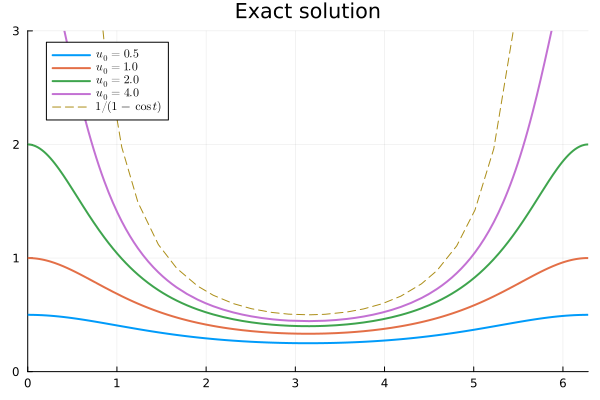

In [2]:
u_exact(t, u₀=1.0) = u₀ / ((1 + u₀) - u₀ * cos(t))

plot(t -> u_exact(t, 0.5);
    xlims=(0, 2π), ylims=(0, 3), lw=2, 
    title="Exact solution", label=L"u_0 = 0.5")
for u₀ ∈ [1.0, 2.0, 4.0]
    plot!(t -> u_exact(t, u₀), lw=2, label=L"u_0 = %$u₀")
end
plot!(t -> 1 / (1 - cos(t)), linestyle=:dash, label=L"1/(1 - \cos t)")

***Exercise 2. (Euler's method)***

(i) ✍️ [3 pts] Use the fundamental theorem of calculus to show that

$$
\begin{align}
    u(t_{j+1}) - u(t_j) = \int_{t_j}^{t_{j+1}} f\big(s, u(s) \big) \,\mathrm{d}s.
\end{align}
$$ {#eq-a4-FTC}

<div class='alert alert-block alert-success'><b>Answer.</b> 




</div> 

(ii) ✍️ [3 pts] Use the rectangular rule on $[t_j, t_{j+1}]$ and @eq-a4-FTC to derive *Euler's method*:

$$
\begin{align}
    u_{j+1} = u_j + h f( t_j, u_j ), \qquad j = 0,\dots, n-1.
\end{align}
$$ {#eq-a4-Euler}

This method is sometimes known as the *explicit* Euler method because $u_{j+1}$ is given explicitly as a function of $u_j$.

<div class='alert alert-block alert-success'><b>Answer.</b> 










</div> 

<div style="break-after: page;"></div>

(iii) 💻 [4 pts] Fix $u_0 = 1$ and $T = 2$. Use ```Euler``` to solve @eq-a4-1iii numerically for $n = 5, 10, 100$ and plot your approximations together with the exact solution.

In [4]:
# your code here

<div class='alert alert-block alert-success'><b>Answer.</b> 










</div> 

(iv) 💻 [5 pts] Plot the errors $e_n := \max\limits_{j = 0,\dots,n} \big| u_j - u(t_j) \big|$ as a function of $n$ (for $n = 1, \dots, 500$, say) on a suitable scale. What is the rate of convergence?

In [5]:
# your code here

<div class='alert alert-block alert-success'><b>Answer.</b> 










</div> 

(v) ✍️ [5 pts] *(Local error.)* Recall from Lecture 10 that the rectangular rule satisfies 
$$
\begin{align}
    \left| \int_a^b g(t) \mathrm{d}t - (b-a) g(a) \right| \leq \frac{\|g'\|_{L^\infty([a,b])}}{2} (b-a)^2.
\end{align}
$$ {#eq-a4-rect}
Suppose that $u_j = u(t_j)$ exactly. Show that the error after one step of Euler's method satisfies

\begin{align*}
    \big| u_{j+1} - u(t_{j+1}) \big| \leq \frac{h^2}{2} \max_{t \in [t_j, t_{j+1}]} |u''(t)|.
\end{align*}

*Hint:* what is $\frac{\mathrm{d}}{\mathrm{d}s} f\big(s, u(s)\big)$?

Explain (heuristically) why this is consistent with the rate of convergence you found in (iv).

<div class='alert alert-block alert-success'><b>Answer.</b> 










</div> 

<div style="break-after: page;"></div>

(vi) ✍️💻 [5 pts] *(Compound interest.)* Consider the initial value problem 
$$
\begin{align}
    u'(t) &= \mu u(t), \\
    u(0) &= 1 \quad \text{on } [0,T].
\end{align}
$$ {#eq-a4-compound}
Show that the exact solution is $e^{\mu t}$. Show that Euler's method gives the sequence of approximations $u_n = \big( 1 + \frac{\mu T}{n} \big)^n$ for $n=1,2,3,\dots$. Compute the rate of convergence on approximating $e^{\mu T}$ (the solution of @eq-a4-compound) with $u_n$ as $n\to\infty$.

In [6]:
# your code here

<div class='alert alert-block alert-success'><b>Answer.</b> 










</div> 

<div style="break-after: page;"></div>

## B: Implicit and other methods [30 pts] {.unnumbered}

***Exercise 3. (Trapezoid method)***

Another approximation uses the trapezoid rule on $[t_j, t_{j+1}]$:

$$
\begin{align}
    u_{j+1} = u_j + \frac{h}{2} \Big[ f\big( t_j, u_j \big) + f\big( t_{j+1}, u_{j+1} \big) \Big]. \nonumber
\end{align}
$$ {#eq-a4-trapezoid}

This is an *implicit* method because we only have an implicit equation for $u_{j+1}$ (that is, $u_{j+1}$ is given by an equation involving $u_{j+1}$). Therefore, to implement this method, we need to solve the nonlinear equation @eq-a4-trapezoid for $u_{j+1}$ at every step.

(i) ✍️ [4 pts] Derive @eq-a4-trapezoid from @eq-a4-FTC. Using the error estimate for the trapezoid rule from Lecture 10, what rate of convergence do you expect for this method?

<div class='alert alert-block alert-success'><b>Answer.</b> 


The lecture 10 formula of trapezoid gives: $
\int_{t_j}^{t_{j+1}}f(s,u(s))\,ds
\approx
\frac{h}{2}\left[f(t_j,u(t_j))+f(t_{j+1},u(t_{j+1}))\right]$.

And from part A, we have: $u(t_{j+1})-u(t_j)=\int_{t_j}^{t_{j+1}}f(s,u(s))\,ds.$

After combing, we have: $$u(t_{j+1})-u(t_j)=\frac{h}{2}\left[f(t_j,u(t_j))+f(t_{j+1},u(t_{j+1}))\right]$$.

We can do some algebraic work by moving $u_j$ to the right to show the eq-a4: 

$$u_{j+1}=u_j+\frac{h}{2} \left[f(t_j,u_j)+f(t_{j+1},u_{j+1})\right]$$


By Theorem 10.2 in Lecture 10, the trapezoid rule on each subinterval $[t_j,t_{j+1}]$ has error bounded by $\frac{\|g''\|_{L^\infty}}{12}(b-a)^3$.

The accumulated global error can be got by accumulating local errors: $nO(h^3)=O(nh^3)=O(h^2)$.

Therefore, the global error is $O(h^2)$.



</div> 

(ii) ✍️ [3 pts] Consider again the problem @eq-a4-1iii. Show that @eq-a4-trapezoid is equivalent to solving $\Phi( u_{j+1} ) = 0$ where

$$
\begin{align}
    \Phi( v ) := v + \tfrac{h}2 \sin( t_{j+1} )  v^2 + \big( \tfrac{h}{2} \sin( t_j ) u_j - 1\big) u_j. 
\end{align}
$$ {#eq-a4-Phi}

<div class='alert alert-block alert-success'><b>Answer.</b> 

The eq-a4-1iii gives the initial condition $f(t, u) = -u^2 \sin(t)$, so eq-a4-trapezoid can be re-written as: $$u_{j+1} = u_j - \frac{h}{2} [u_j^2 \sin(t_j) + u_{j+1}^2 \sin(t_{j+1})]$$
Then we can find the common factor of the two terms: $u_{j+1} = u_j( - \frac{h}{2} u_j \sin(t_j) +1 )+ \frac{h}{2}u_{j+1}^2 \sin(t_{j+1})$

Then we can move everything to the right hand side and change the sign: $$0=u_{j+1} + \frac{h}{2} \sin(t_{j+1}) u_{j+1}^2 + \left(\frac{h}{2} \sin(t_j) u_j - 1\right) u_j$$

Now it is clear that $v=u_{j+1}$, so we can simplily substitute to show that: $$\Phi(v) = v + \frac{h}{2} \sin(t_{j+1}) v^2 + \left(\frac{h}{2} \sin(t_j) u_j - 1\right) u_j$$

</div> 

(iii) ✍️ [5 pts] Explain why, for all sufficiently small $h$, Newton's method applied to $\Phi$ and starting at the Euler step $v_1 := u_j - h u_j^2 \sin( t_j )$ converges quadratically to some $u_{j+1}$ satisfying $\Phi( u_{j+1} ) = 0$.

*Hint:* use the theorem on the convergence of Newton's method from Lecture 5. What are $\Phi'$ and $\Phi''$? What happens to $\left|\frac{\Phi''(x)}{\Phi'(y)}\right|$ as $h \to 0$?

<div class='alert alert-block alert-success'><b>Answer.</b> 

It is obvious to see that $\Phi(v)$ is twice continuously differentiable and $\Phi(v)$ has a root where its derivative value ar root is zero. So we can apply thm 5.3 to show that at least quadratically, by testing if $\left| \frac{\Phi''(x)}{\Phi'(y)} \right| \le A$:
$\Phi'(v) = 1 + h \sin(t_{j+1}) v$ and $\Phi''(v) = h \sin(t_{j+1})$.

THen, $\left| \frac{\Phi''(x)}{\Phi'(y)} \right| = \left| \frac{h \sin(t_{j+1})}{1 + h \sin(t_{j+1})y} \right|$.

Since $|\sin(t_{j+1})|$ is bounded by 1 and as n increase to infinitely large, h will approach 0. Then $\lim_{h \to 0} \left| \frac{\Phi''(x)}{\Phi'(y)} \right| = 0$. It implies that for a sufficiently small h, $\left| \frac{\Phi''(x)}{\Phi'(y)} \right|$ is bounded by some constant $A>0$. Therefore, by thm 5.3, it converges at least quadraticlly.

</div> 

(iv) 💻 [5 pts] Complete the following code to implement the trapezoid method @eq-a4-trapezoid using ```Newton``` (starting at the Euler step) for a general $f$. Here, ```df_du(t, u)``` is the partial derivative $\frac{\partial f}{\partial u}(t,u)$. Plot your approximation of @eq-a4-1iii (with $u_0 = 1$, $T = 2$ and $n = 5$) together with the Euler approximation and the exact solution.

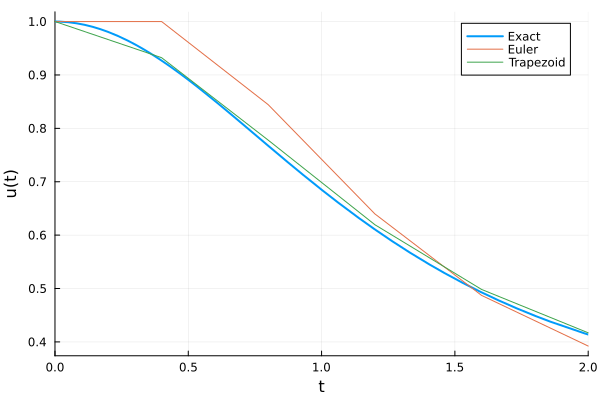

In [6]:
function Trapezoid(f, df_du, u0, T, n)
    h = T / n
    t = 0:h:T
    u = zeros(n + 1)
    u[1] = u0
    for j ∈ 1:n
        # your code here: define Φ and Φ' and use Newton to compute u[j+1]
        Φ(v) = v - u[j] - h*(f(t[j], u[j]) + f(t[j+1], v))/2
        Φ′(v) = 1 - h*df_du(t[j+1], v)/2
        initial = u[j] + h*f(t[j], u[j])
        u[j+1], k = Newton(Φ, Φ′, initial)
    end
    return u
end

t = 0:(2/5):2.0

u_euler = Euler(f, 1.0, 2.0, 5)
u_trap = Trapezoid(f, df_du, 1.0, 2.0, 5)

plot(t -> u_exact(t, 1.0), xlims=(0, 2.0),
     lw=2, label="Exact",
     xlabel="t", ylabel="u(t)")

plot!(t, u_euler, label="Euler")

plot!(t, u_trap, label="Trapezoid")


<div class='alert alert-block alert-success'><b>Answer.</b> 




We can see that Euler plot approxiamte slower and has a bigger global error.





</div> 

(v) 💻 [4 pts] Plot the errors of the Euler and trapezoid methods as functions of $n$ on the same graph. What is the rate of convergence of the trapezoid method? Does this agree with your answer to (i)?

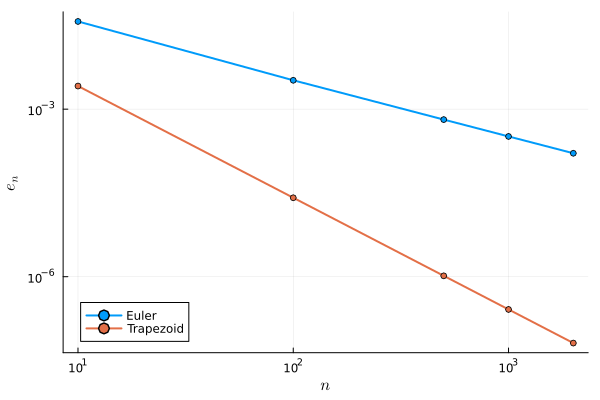

1.004444141991935
1.9999727657264372


In [24]:

u0 = 1.0
T = 2.0
ns = [10, 100, 500, 1000, 2000]

E_euler = errors(Euler, f, u0, T, ns, u_exact)

function trap(f, u0, T, n)
    return Trapezoid(f, df_du, u0, T, n)
end

E_trap = errors(trap, f, u0, T, ns, u_exact)

p = plot()
plot_errors!(p, ns, E_euler, "Euler")
plot_errors!(p, ns, E_trap, "Trapezoid")
display(p)

println(rate(ns, E_euler))
println(rate(ns, E_trap))

<div class='alert alert-block alert-success'><b>Answer.</b> 


It agrees with our answers in (i). This is a log-log plot where the slope represents for convergence rate -p. It is obvious that Trapezoid's converge rate is $O(h^2)$ globally.







</div> 

***Exercise 4. (Other ways of solving the nonlinear equation in Trapezoid)***

(i) ✍️💻 [5 pts] Instead of Newton's method, we could solve @eq-a4-trapezoid using the simple iteration $v_{k+1} = G(v_k)$ where

\begin{align*}
    G(v) := u_j + \frac{h}{2} \Big[ f\big( t_j, u_j \big) + f\big( t_{j+1}, v \big) \Big].
\end{align*}

For the example @eq-a4-1iii, compute $G'(v)$ and explain why $G$ is a contraction on $[u_j - 1, u_j + 1]$ for all sufficiently small $h$ (you may assume $|u_j| \leq 2$). Implement this version of the trapezoid method and compare the **total** number of iterations used by Newton's method and by the simple iteration (with the same tolerance) for $n = 20$. Which would you use, and why?

In [9]:
# your code here

<div class='alert alert-block alert-success'><b>Answer.</b> 










</div> 

(ii) ✍️💻 [4 pts] *(Heun's method.)* We can avoid solving a nonlinear equation by replacing $u_{j+1}$ on the right-hand side of @eq-a4-trapezoid with the Euler step $\widetilde u_{j+1} := u_j + h f(t_j, u_j)$:

\begin{align*}
    u_{j+1} = u_j + \frac{h}{2} \Big[ f\big( t_j, u_j \big) + f\big( t_{j+1}, \widetilde u_{j+1} \big) \Big].
\end{align*}

Implement this method and add its errors to your plot from Exercise 3 (v). What is its rate of convergence? How many evaluations of $f$ does each step require?

In [10]:
# your code here

<div class='alert alert-block alert-success'><b>Answer.</b> 










</div> 

<div style="break-after: page;"></div>

## C: Runge–Kutta and comparing the methods [20 pts] {.unnumbered}

***Exercise 5. (Runge–Kutta)***

The *classical Runge–Kutta method* (RK4) is

\begin{align*}
    k_1 &= f(t_j, u_j), \nonumber\\ 
    k_2 &= f\big(t_j + \tfrac{h}{2}, u_j + \tfrac{h}{2} k_1\big), \nonumber\\
    k_3 &= f\big(t_j + \tfrac{h}{2}, u_j + \tfrac{h}{2} k_2\big), \nonumber\\
    k_4 &= f(t_{j+1}, u_j + h k_3),
\end{align*}

and $u_{j+1} = u_j + \frac{h}{6} ( k_1 + 2 k_2 + 2 k_3 + k_4 )$.

(i) 💻 [10 pts] Implement RK4 as ```RK4(f, u0, T, n)``` and apply it to @eq-a4-1iii (with $u_0 = 1$ and $T = 2$). Using ```errors``` and ```plot_errors!``` from the code at the start, plot the errors of Euler, Heun, trapezoid and RK4 as functions of $n$ (for example ```ns = unique(round.(Int, 10 .^ range(0, 2.5, length=15)))```) on the same graph. Use ```rate``` to estimate the rate of convergence of each method. What is the rate of RK4? Do your rates agree with what you expect from the quadrature rule behind each method?

In [ ]:
# your code here

<div class='alert alert-block alert-success'><b>Answer.</b> 










</div> 

<div style="break-after: page;"></div>

(ii) ✍️💻 [10 pts] *(Efficiency.)* How many evaluations of $f$ does each step of Euler, Heun and RK4 require? Check this using ```counted```. Plot the errors of these three methods against the total number of evaluations of $f$. Approximately how many evaluations does each method need to obtain an error of at most $10^{-6}$? Which method would you use?

In [ ]:
# your code here

<div class='alert alert-block alert-success'><b>Answer.</b> 










</div> 

<div style="break-after: page;"></div>


## D: Reflection (individual) [20 pts] {.unnumbered}

**This section is completed individually, not as a group.** Do **not** include it in the group notebook: fill in your own copy (or write your answers in an email) and **email it to me** before the deadline.

**Goal:** Reflect on your learning strategies, track your workload, reflect on working in a group, and help us improve future course material.  
**Time:** take 5-10 mins (this shouldn't take too long)

Estimate the approximate hours you spent:   
* **Assignment:**              ____   
* **Reading notes/materials:** ____    
* **Exercises:**               ____   

(Reminder: you should be spending around 8 hours per week on this course outside of the 4 hours of lectures)

<div class='alert alert-block alert-success'><b>Any other comments:</b> 










</div> 


Take a moment to reflect on your learning over the past few weeks:

What was the easiest topic or task and why? Where did you struggle, and how did you overcome those challenges? Which resources (e.g. lecture notes, practice exercises, peer discussions, ...) helped you the most? How did you manage your time and workload? Looking back, what would you do differently if you were starting again?

<div class='alert alert-block alert-success'><b>Comments:</b> 










</div> 


**Working in a group.** Answer the following about this group project:

1. How did your group divide the work and make decisions (e.g. who did what, how often and where did you meet)? What worked well, and what would you change next time?
2. What did *you* personally contribute to the submission, and which parts of the other members' work did you check or learn from?
3. Describe a moment when you disagreed or got stuck as a group. How did you resolve it?
4. Can you explain every part of the submission, including the parts written by others? Which part would you find hardest to explain?
5. Compared with working alone on earlier assignments, what did you gain or lose from working in a group?

<div class='alert alert-block alert-success'><b>Comments:</b> 










</div> 


(Optional) Any changes that would improve the lectures, exercises, or assignments for the future? You can also suggest things anonymously <a href="http://z.umn.edu/JT-message" 
     class="btn btn-outline-info btn-sm" 
     target="_blank" 
     rel="noopener noreferrer">
    <i class="bi bi-archive me-1" aria-hidden="true"></i>
    here
    <span class="visually-hidden">(opens in a new tab)</span>
  </a> 

<div class='alert alert-block alert-success'><b>Comments:</b> 










</div> 


## OPTIONAL SECTIONS {.unnumbered}

These questions are optional extra practice. Together they are worth up to **10 bonus pts** (do the questions that sound interesting to you).

**Optional 1. (Simpson and RK4)** ✍️ Applying Simpson's rule on $[t_j, t_{j+1}]$ to @eq-a4-FTC involves $u(t_j + h/2)$ and $u(t_{j+1})$: why can't this be used directly as a method? If $f(t,u) = g(t)$ does not depend on $u$, show that RK4 reduces to Simpson's rule on each $[t_j, t_{j+1}]$, and deduce $|u(T) - u_n| = O(n^{-4})$ for smooth $g$.

**Optional 2. (Stability)** ✍️💻 Consider $u' = \lambda u$, $u(0) = 1$, and $\lambda < 0$. What is the exact solution and what happens in the long-time limit $t\to\infty$. Show that Euler gives $u_j = (1 + h\lambda)^j$ and trapezoid gives $u_j = \big(\frac{1 + h\lambda/2}{1 - h\lambda/2}\big)^j$. For which $h > 0$ do each of these numerical solutions decay to $0$? Check numerically with $\lambda = -10$, $T = 2$ and $n = 9, 11, 20$.

In [ ]:
# your code here

**Optional 3. (Logistic equation)** ✍️💻 Let $P' = rP(1 - P/K)$, $P(0) = P_0$, with exact solution $P(t) = \frac{P_0 K e^{rt}}{K - P_0 + P_0 e^{rt}}$, $r = 3$, $K = 20$, $P_0 = 22$, $T = 10$. Plot Euler with $n = 5, 10, 20, 100$ against the exact solution. Writing $P = K + w$, show $w' \approx -rw$ and explain what you see using Optional 2.

In [ ]:
# your code here

**Optional 4. (Backward Euler)** The method $u_{j+1} = u_j + h f(t_{j+1}, u_{j+1})$ is implicit.  
(a) ✍️ For $u' = \lambda u$ with $\lambda < 0$, for which $h > 0$ does $u_j \to 0$?  
(b) 💻 Implement it (with ```Newton```) and check the $O(n^{-1})$ error for @eq-a4-1iii.  
(c) 💻✍️ On the problem $u' = -50(u - \cos t)$, $u(0)=0$ on $[0,1]$, compare Euler and backward Euler for $h = 0.05, 0.025$ and explain.

In [ ]:
# your code here

<div style="break-after: page;"></div>

**Optional 5. (Richardson extrapolation)** Suppose Euler's method produces the sequence of approximations $u^{(n)} = (u^{(n)}_0, ..., u^{(n)}_n)$ and the error is $u(T) - u^{(n)}_n \approx C n^{-1}$.  
(a) ✍️ Show that $R_n := 2u^{(2n)}_{2n} - u^{(n)}_n$ decays faster.  
(b) 💻 Plot the errors of $u^{(n)}_n$ and $R_n$ for @eq-a4-1iii. What is the rate of $R_n$?  
(c) ✍️💻 Assuming the error of $R_n$ is $\approx Dn^{-2}$, extrapolate again from $R_n$ and $R_{2n}$ and test it.

In [ ]:
# your code here

**Optional 6. (Adams–Bashforth)** Replace $s \mapsto f(s,u(s))$ in @eq-a4-FTC by the linear interpolant of $f_{j-1}, f_j$.  
(a) ✍️ Show this gives $u_{j+1} = u_j + \frac h2(3f_j - f_{j-1})$.  
(b) 💻 Implement it (use one Heun step for $u_1$), find its rate for @eq-a4-1iii and count evaluations of $f$ per step.  
(c) ✍️ Explain the rate using the interpolation error from Lecture 6.

In [ ]:
# your code here

**Optional 7. (Hermite method)** Use $\int_a^b g \approx \frac{b-a}{2}[g(a)+g(b)] + \frac{(b-a)^2}{12}[g'(a)-g'(b)]$ in @eq-a4-FTC.  
(a) ✍️ Show $\frac{\mathrm d}{\mathrm ds} f(s,u(s)) = f_t + f_u f$ and compute it for @eq-a4-1iii.  
(b) 💻 Implement the implicit method (Newton or simple iteration).  
(c) 💻✍️ Find the rate and explain it with the error bound $\frac{\|g^{(4)}\|}{720}(b-a)^5$.

In [ ]:
# your code here

<div style="break-after: page;"></div>

**Optional 8. (Lotka–Volterra)** Let 
$$
\begin{align}
    x' &= \alpha x - \beta xy, \nonumber\\
    y' &= \delta xy - \gamma y
\end{align}
$$ 
with $\alpha = 1.1$, $\beta = 0.4$, $\gamma = 0.4$, $\delta = 0.1$, $x(0)=y(0)=10$, $T = 50$ (use $h \le 0.05$).  
(a) 💻 Make Euler and RK4 work for vectors; plot $x, y$ against $t$ and $y$ against $x$.  
(b) ✍️ Show $V = \delta x - \gamma\log x + \beta y - \alpha\log y$ is constant on exact solutions.  
(c) 💻 Plot $V$ along both numerical solutions and comment.

Hint: see [Math 5486](https://jack.thomaslabs.co.uk/teaching/Math5486-Spring-2026/A2.html)

In [ ]:
# your code here

**Optional 9. (Pendulum)** Let 
$$\begin{align}
    \theta'(t) &= \omega(t), \nonumber\\ 
    \omega'(t) &= -\sin\big(\theta(t)\big), 
\end{align}
$$
with $\theta(0)=1$ and $\omega(0)=0$.  
(a) ✍️ Show $E = \frac12\omega^2 - \cos\theta$ is constant on exact solutions.  
(b) 💻 Plot $E$ for Euler with $h = 0.1$, $T = 100$.  
(c) 💻 Repeat with the method $\omega_{j+1} = \omega_j - h\sin\theta_j$, $\theta_{j+1} = \theta_j + h\omega_{j+1}$, and plot $\omega$ against $\theta$ for both.

In [ ]:
# your code here

**Optional 10. (Blow-up time)** Take @eq-a4-1iii with $u_0 = -\frac23$.  
(a) ✍️ Show $w = 1/u$ solves $w' = \sin t$ and find the blow-up time $t^\ast$.  
(b) 💻 Apply Euler and RK4 on $[0,4]$ with $n = 100, 1000$. What happens near $t^\ast$? (The values overflow to `Inf`/`NaN` after $t^\ast$: plot only up to just after $t^\ast$, or set `ylims`.)  
(c) 💻✍️ Estimate $t^\ast$ by solving $w' = \sin t$ numerically and finding a root of the interpolant of $(t_j, w_j)$. How does the error depend on $n$?

In [ ]:
# your code here